In [2]:
#| include: false
# Phase 1 of the migration onto source/cover.py: this notebook holds no model
# code of its own. Everything that computes a cover balance or a price lives in
# the module, where it is documented and doctested.
import sys

sys.path.insert(0, "../source")
import cover

# Parameters, fixed throughout, carrying the paper's symbols. Two rates, and
# they are not the same number: rho is the Facility's, r is the borrower's.
n = 15                      # tenor, in years: 15 debt-service payments
rho = 0.05                  # facility discount rate: what the Facility values
                            # its own liability at and annuitises the loss at.
                            # Everything on the experience account runs at this rate
                            # -- V_w, Theta, Psi all depend on rho alone.
r = 0.10                    # borrower cost of capital: what a hard-currency
                            # project in the region actually pays. It enters in
                            # one place only, at the very end, to restate the
                            # premium as a margin (Delta r). It must not reach
                            # any cover-side quantity.
start_year = 1995           # sample opens here unless a cell says otherwise
A = cover.annuity(n, rho)   # annuity factor of facility A_{n,rho}

# Lesotho is excluded from the panel: its CPI carries uncorrected basket and
# base-year breaks in 1999, 2002 and 2009, which show up in X as jumps of the
# same size as the devaluations the instrument is meant to cover. Nothing in
# the data distinguishes the two, so the country is dropped rather than
# patched. `drop` is passed explicitly so the exclusion is visible in the
# draft rather than buried in a default.
df = cover.load_panel(drop=("LSO",))

print(f"panel: {df.iso3.nunique()} countries, {int(df.year.min())}-{int(df.year.max())}, "
      f"n = {n}, rho = {rho:.0%}, r = {r:.0%}, A_n,rho = {A:.4f}")


panel: 53 countries, 1985-2024, n = 15, rho = 5%, r = 10%, A_n,rho = 10.3797


# Motivation: the currency mismatch that blocks the deal

Currency mismatch between local currency revenues in developing countries and the cost of hard currency debt service holds up many infrastructure finance transactions. When such hard currency credit has been provided for developing country electricity generation infrastructure, the currency risk has often been placed on the national utility - "offtaker" - through dollarised power purchase agreements (PPAs). This has led to an exacerbation of these utilities' financial woes from currency devaluations. This has had the knock-on effect of increasing offtaker risk for such projects and generating an additional impediment to the financing of electricity generation projects. Capital costs for such projects are thus affected two-fold by the currency mismatch, by the direct currency risk and by the induced offtaker risk.

This analysis suggests that, when inflation is borne by the consumer, the residual - real - currency risk, is limited when borne by an institution with sufficiently long term capital. This is due to the relatively long period in the cyclicality of the real exchange rate. An institution exposed to real exchange rate risk and able to weather adverse movements lasting 5-10 years will bear significantly less risk than is commonly assumed, even for developing country currency risk. As a result, such institutions are well placed to offer affordable cover to such transactions.

This proposal, analogous to the emergency liquidity facility of the EcoInvest Brazil platform provided by the IaDB, provides insurance against shortfalls in hard currency debt service *triggered by adverse movements the exchange and inflation rates*. The pre-requisite for cover is that revenues are indexed to local currency inflation through appropriate clauses in the power purchase agreement. As we show below, this strips inflation out of the nominal exchange rate risk, leaving only a real exchange rate risk component, which is bounded and cyclical, and consequently allows for affordable cover.

## Notation

**Unit of observation:** a *window* $w=(i,\underline{t})\in\mathcal{W}$ — country $i$, base date at $\underline{t}$. Given a set of countries in the insurance pool and a tenor $n$ on the debt, $\mathcal{W}$ is the set of $n$-year windows available in the World Development Indicator (WDI) dataset used in this analysis, indexed by the country and base date of the window. Windows share the common length (which will be clear from the context) but start at different base dates.

- $A_{n,\varrho}=\sum_{k=1}^{n}(1+\varrho)^{-k}=\dfrac{1-(1+\varrho)^{-n}}{\varrho}$ — the annuity factor between $n$ level payments and their present value, at discount rate $\varrho$
- $r$ — loan interest rate (cost of capital of borrower)
- $\rho$ — facility discount rate (cost of capital of the insurer)
- $\bar\delta$ — level annual debt service:  $D=A_{n,r}\cdot\bar\delta$ — debt stock/principal
- $P_{i,t}$ — domestic price level (CPI), in LCU; $p\equiv\ln P$, inflation $\dot p$
- $P^{*}_{t}$ — US price level; $p^{*}\equiv\ln P^{*}$, US inflation $\dot p^{*}$
- $S_{i,t}$ — nominal exchange rate in LCU per USD, so $\dot s>0$ is a depreciation of the local currency; $s\equiv\ln S$
- $X_{i,t}\equiv P_{i,t}/S_{i,t}$ — the **dollar unit-revenue index**: the nominal USD value of a fixed domestic basket, i.e. what a kWh of inflation-indexed local revenue is worth in dollars. It is *not* the real exchange rate
- $Q_{i,t}\equiv X_{i,t}/P^{*}_{t}$ — the real exchange rate.
- $R_w(k)\equiv X_{i,\underline{t}+k}/X_{i,\underline{t}}-1$, for $k=0,\dots,n$ — cumulative (holding-period) return on $X$ since the base date, so $R_w(0)=0$
- $\text{PL}_w(k)=\bar\delta\,R_w(k)$ — the P&L in the $k$-th year of debt service: the dollar surplus or shortfall against debt service
- $\Lambda_w(n)\equiv\bar\delta\sum_{k=1}^{n}R_w(k)(1+\rho)^{-k}$ — the discounted present value of P&L after $n$ years
- $V_w(n)\equiv\sum_{k=1}^{n}R_w(k)(1+\rho)^{-k} = \Lambda_w(n)/\bar\delta$, — balance of the experience account after $n$ years, measured in years of debt service valued at the base date
- $L_w(n)\equiv\bar\delta(-V_w(n))^+$ — ultimate net loss to the Facility over window $w$ with length $n$
- $\Theta(n)\equiv\frac{1}{N}\sum_{w\in\mathcal{W}}(-V_w(n))^+$ — the **expected loss in years of debt service**, $\mathbb{E}_N[L_w]/\bar\delta$
- $\Psi(n) \equiv \dfrac{\Theta(n)}{A_{n,\rho}}$ — the level annual premium as a fraction of the level annual debt service.
- $\Delta r$ in $A_{n,\;r+\Delta r} \;=\; \frac{A_{n,r}}{1 + \Psi}$ — margin-equivalent interest-rate spread

- $V_w\equiv V_w(n)$ — the **net cover balance**: the terminal balance of the experience account in years of debt service, at the tenor of the debt, when there is no risk of confusion from dropping $n$

## A stylised project

The analysis below focuses on the **dollar unit-revenue index** $X_{i,t}=P_{i,t}/S_{i,t}$, where $P_{i,t}$ is the domestic price level and $S_{i,t}$ the nominal exchange rate in LCU per USD. As an index, $X$ measures the change in the USD value of a fixed local basket of goods. If the local price of electricity is made to grow at the national inflation rate, $X$ also measures the evolution of the USD value of a kWh sold domestically. It is easy to see (and we show in detail below) that when tariffs are inflation-adjusted, $X$ is a good measure of the dollar cash flows available for debt service.

Consider, for simplicity, a project in country $i$ with base date $\underline{t}$ (which we denote with the shorthand for window $w=(i,\underline{t})\in\mathcal{W}$) and generating a constant amount of energy $\bar{E}$ over the $n$ years of its debt service, at constant real unit cost $c$, excluding hard-currency debt service, and selling at an inflation-indexed real tariff $\mathcal{T}$. Nominal local-currency revenue is $P_{i,t}\,\mathcal{T}\,\bar{E}$ and earnings before debt service are $P_{i,t}(\mathcal{T}-c)\bar{E}$. That is, local-currency cash flows available for debt service (CFADS) are a constant growing at the rate of inflation, and CFADS in dollars are

$$
\text{CF}^{\$}_w(k) \;\equiv\; X_{i,\underline{t}+k}\,(\mathcal{T}-c)\,\bar{E},
\qquad k=0,\dots,n .
$$

For the sake of exposition, we consider a stylised project in which all debt service is in hard currency and a constant $\bar\delta$ dollars over the entire repayment period.

We will assume that the debt has been sized so that annual debt service is exactly equal to the dollar CFADS observed in the base year: $\bar\delta = \text{CF}^{\$}_w(0) \equiv X_{i,\underline{t}}(\mathcal{T}-c)\bar{E}$

This automatically results in a debt service coverage ratio (DSCR) of one at the base date, leaving zero buffer for future FX swings; dollar debt service is constant by assumption and CFADS only just cover the debt service requirement when $X_{i,t} = X_{i,\underline{t}}$ is constant. The assumption also implies zero profit in the constant $X$ scenario, a debt service shortfall (and technical default) when $X$ decreases and a surplus when $X$ increases.

Project finance structures usually require a DSCR greater than 130% as a buffer against various risks to which the cash flows are exposed. Still, our assumption of zero buffer is without loss of generality, since the main affordability result below is only strengthened if debt is sized more conservatively and the projected $\text{DSCR}_t>1$, especially if the project (credit) risk is less than fully correlated with the macro risk that we propose to insure against.

Mathematically the P&L (surplus or shortfall) in the $k$-th year of debt service due to currency or price movements is simply the dollar CFADS minus the dollar debt sevice:
$$
\text{PL}_w(k) = \text{CF}^{\$}_w(k) - \bar\delta = \bar\delta \frac{\text{CF}^{\$}_w(k) - \text{CF}^{\$}_w(0)}{\text{CF}^{\$}_w(0)} = \bar\delta \cdot  R_w(k)
$$
where
$$
R_w(k) \;\equiv\; \frac{\text{CF}^{\$}_w(k)}{\text{CF}^{\$}_w(0)} - 1 \;=\; \frac{X_{i,\underline{t}+k}}{X_{i,\underline{t}}} - 1
$$

is the cumulative return on $X$ since the base date — a holding-period return, not a per-period flow — since the debt is sized so that debt service is equal to the base-year cash flow.

Given a discount rate $\rho$, the discounted present value of the P&L is

$$
\Lambda_w(n) \;=\; \sum_{k=1}^{n}\bar\delta\, \frac{R_w(k)}{(1+\rho)^{k}} \;=\; \bar\delta \cdot \underbrace{\sum_{k=1}^{n} \frac{R_w(k)}{(1+\rho)^{k}}}_{V_w(n)}
$$

This is the value at time $\underline t$ of receiving (and having to pay) the project's dollar cashflows net of its debt service cost each year over $n$ years, to a party with discount rate $\rho$. As such it captures the net impact of the currency mismatch between the project's cashflows and the loan it is using to finance itself. We can make this a property purely of the macroeconomic environment rather than of the specific size of the loan, by dividing out the project's level annual debt service, and thus measuring it in units of *years of debt service*. This defines our *net cover balance*, for which we drop the argument $n$ when there is no ambiguity on the tenor:
$$
V_w = V_w(n)  \equiv \sum_{k=1}^{n} \frac{1}{(1+\rho)^{k}} \frac{X_{i,\underline{t}+k}- X_{i,\underline{t}}}{X_{i,\underline{t}}} \;=\; \frac{\Lambda_w(n)}{\bar\delta}
$$

$V_w=-1$ is a hole worth exactly one annual debt-service payment, whatever the tenor. As was the objective, this is a purely macroeconomic property in that two equal-length windows of the same country with different base dates therefore differ only in the limits of this sum and in the level $X_{i,\underline{t}}$ against which the path is measured.


V(1998-2006) = -0.76 yrs of debt service   (valued at 1998)
V(2006-2013) = +1.15 yrs of debt service   (valued at 2006, +0.78 carried back to 1998)
V(1998-2013) = -0.03 yrs of debt service   on X, the whole window
V(1998-2013) = -2.07 yrs of debt service   on 1/S: unindexed dinar revenue


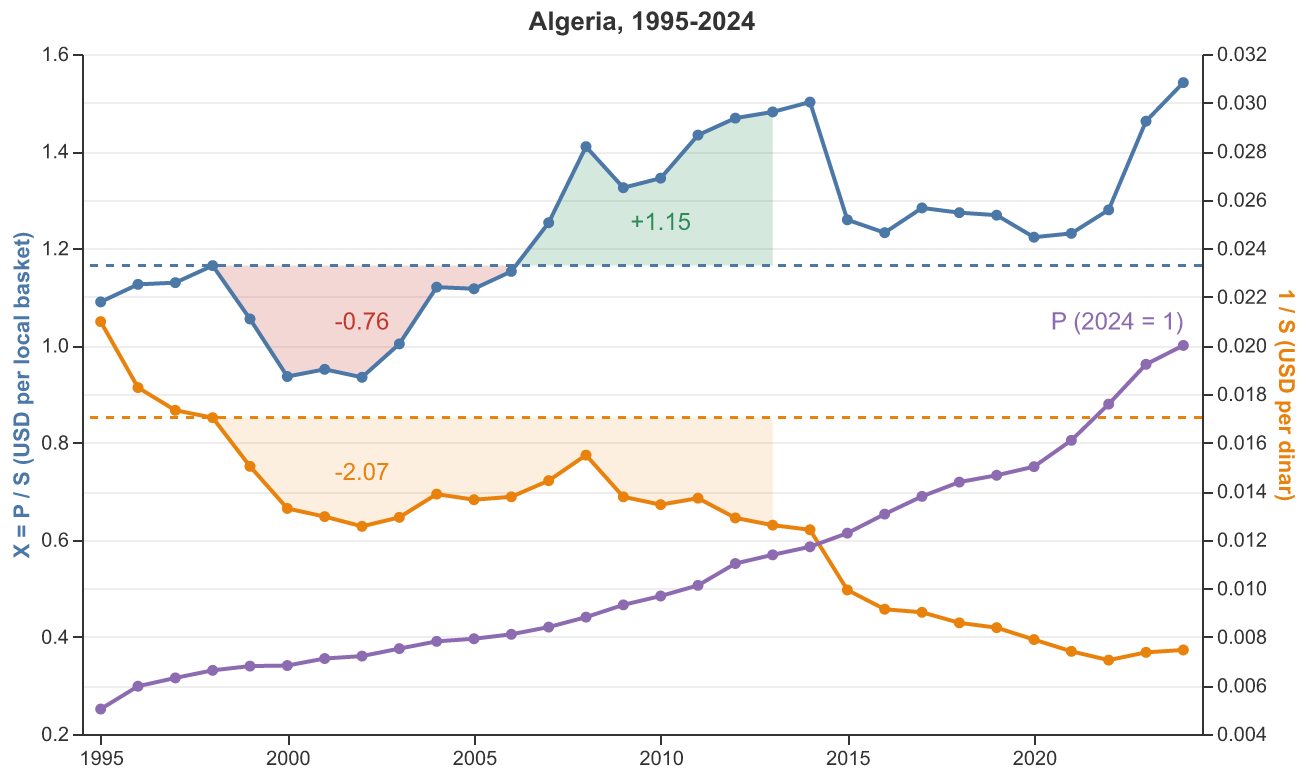

In [3]:
#| label: fig-algeria
#| fig-cap: "Algeria, 1995-2024. Left axis: the dollar unit-revenue index $X=P/S$, what a fixed local basket is worth in dollars, and alongside it the price level $P$ itself, normalised to 1 in 2024 --- $X$ is that smooth climb netted against the dinar's fall. Right axis: the nominal rate $1/S$. Dashed lines mark the 1998 base-year level each series is struck at, and each shaded area is labelled with its $V$, the net cover balance in years of debt service, valued at the start of its own segment. A project with its base date in 1998 with an inflation-indexed tariff runs eight years of shortfall against its base-year level (red, $V=-0.76$) and seven of surplus (green, $V=+1.15$ at 2006, $+0.78$ carried back to the base date); over the full window the two all but cancel, at $V=-0.03$ years of debt service. Had the same revenue been fixed in dinar, it would have been short for all fifteen years (orange, $V=-2.07$)."
import altair as alt
import pandas as pd

alt.renderers.enable("png", scale_factor=2.0)


@alt.theme.register("paper", enable=True)
def _paper_theme():
    """White ground and dark ink, whatever theme the notebook viewer imposes."""
    ink = "#333333"
    return {"config": {
        "background": "white",
        "view": {"strokeWidth": 0},
        "title": {"color": ink},
        "axis": {"labelColor": ink, "titleColor": ink, "tickColor": ink,
                 "domainColor": ink, "gridColor": "#eeeeee"},
        "text": {"color": ink},
    }}

# --- the numbers, from the module -------------------------------------------
# cover_balance() takes one stretch of series -- the base-year level first,
# then the fixings -- and returns V in years of debt service. Each segment is
# valued at the start of its own segment, so V_green is a 2006 figure and has
# to be carried back eight years before it can be set against V_red.
dza = df[(df.iso3 == "DZA") & df.year.between(1995, 2024)].sort_values("year")
dza = dza.assign(P=dza.cpi / float(dza.loc[dza.year == 2024, "cpi"].iloc[0]))


def V(t0, t1, col="X"):
    return cover.cover_balance(dza.loc[dza.year.between(t0, t1), col].to_numpy(), rho)


V_red, V_green = V(1998, 2006), V(2006, 2013)
V_window, V_nominal = V(1998, 2013), V(1998, 2013, "usd_per_lcu")
V_green_at_close = V_green * (1 + rho) ** -8

print(f"V(1998-2006) = {V_red:+.2f} yrs of debt service   (valued at 1998)")
print(f"V(2006-2013) = {V_green:+.2f} yrs of debt service   (valued at 2006, "
      f"{V_green_at_close:+.2f} carried back to 1998)")
print(f"V(1998-2013) = {V_window:+.2f} yrs of debt service   on X, the whole window")
print(f"V(1998-2013) = {V_nominal:+.2f} yrs of debt service   on 1/S: unindexed dinar revenue")

# --- the panel ---------------------------------------------------------------
# Colour says which series a mark belongs to -- blue for X, orange for the
# nominal rate, purple for the price level -- and each is named where it sits,
# in its own colour, so the figure carries no legend. Red and green are
# reserved for the sign of the balance: shortfall against the strike, surplus
# above it.
BLUE, ORANGE, RED, GREEN, PURPLE = "#4c78a8", "#e8820c", "#c0392b", "#2e8b57", "#8c6bb1"
X_1998 = float(dza.loc[dza.year == 1998, "X"].iloc[0])
S_1998 = float(dza.loc[dza.year == 1998, "usd_per_lcu"].iloc[0])

# The two y-domains are pinned rather than fitted, and pinned to these numbers
# so that the three shaded areas occupy disjoint bands of the plot: inside its
# window 1/S runs 0.0126-0.0170, the 31%-47% stripe of the right domain, while
# X runs 0.93-1.48, the 52%-91% stripe of the left. Fitted axes put the orange
# area straight through the red and green ones. Both domains have to be
# repeated on every y encoding in their layer: mark_area defaults to a
# zero-anchored scale, and any layer that leaves the scale unset silently
# unions its own domain into the one set next door.
LEFT = alt.Scale(domain=(0.2, 1.6), nice=False)
RIGHT = alt.Scale(domain=(0.004, 0.032), nice=False)
YEAR = alt.X("year:O", title=None,
             axis=alt.Axis(labelAngle=0, values=list(range(1995, 2025, 5))))


def line(col, colour):
    """A series in its own colour. The point overlay takes that colour
    explicitly: `point=True` leaves the markers at Vega-Lite's default blue,
    whatever the line itself is drawn in."""
    return alt.Chart(dza).mark_line(
        point=alt.OverlayMarkDef(color=colour), color=colour).encode(
        x=YEAR, tooltip=["year", alt.Tooltip(f"{col}:Q", format=".4f")])


def panel(col, title, colour, orient, strike, scale, bands, opacity=0.2):
    """Everything on one axis: the series, its base-year strike, and the
    shaded areas between the two.

    A band is ``(t0, t1, colour, V, at)``: the segment, the colour of its sign,
    the balance that labels it, and where along the segment that label sits --
    0 at the close and 1 at maturity, so a lower value moves it clear of a
    crowded middle. The label lands midway between the series and the strike,
    inside its own shading. Every band on an axis shares one frame and one
    mark, keyed by colour, and the strike is a constant rather than a column,
    so an axis is four marks however many bands it carries.
    """
    seg = pd.concat([dza[dza.year.between(t0, t1)].assign(band=c)
                     for t0, t1, c, _, _ in bands])
    tags = []
    for t0, t1, c, v, at in bands:
        anchor = dza[dza.year.between(t0, t1)].iloc[round(at * (t1 - t0))]
        tags.append({"year": int(anchor.year), "band": c, "label": f"{v:+.2f}",
                     "y": (float(anchor[col]) + strike) / 2})

    sign = alt.Color("band:N", scale=None, legend=None)
    return (
        alt.Chart(seg).mark_area(opacity=opacity).encode(
            x=YEAR, y=alt.Y(f"{col}:Q", scale=scale), y2=alt.datum(strike), color=sign)
        + alt.Chart(pd.DataFrame(tags)).mark_text(fontSize=12).encode(
            x=YEAR, y=alt.Y("y:Q", scale=scale), text="label:N", color=sign)
        + alt.Chart(dza).mark_rule(
            color=colour, strokeDash=[4, 4], opacity=0.8).encode(y=alt.datum(strike))
        + line(col, colour).encode(
            y=alt.Y(f"{col}:Q", title=title, scale=scale,
                    axis=alt.Axis(orient=orient, titleColor=colour)))
    )


# P shares X's axis because X = P * (1/S): putting the two on one scale is what
# makes X's path legible as the price level netted against the nominal rate.
# It is named on the line, at its 2024 end, rather than in a legend.
price_level = (
    line("P", PURPLE).encode(y=alt.Y("P:Q", scale=LEFT))
    + alt.Chart(dza[dza.year == 2024]).mark_text(
        color=PURPLE, fontSize=12, dy=-12, align="right").encode(
        x=YEAR, y=alt.Y("P:Q", scale=LEFT), text=alt.datum("P (2024 = 1)"))
)

# The nominal panel is drawn first, and shaded lighter, so the indexed one
# layers on top of it rather than the other way about.
alt.layer(
    panel("usd_per_lcu", "1 / S   (USD per dinar)", ORANGE, "right", S_1998, RIGHT,
          [(1998, 2013, ORANGE, V_nominal, 0.25)], opacity=0.13),
    panel("X", "X = P / S   (USD per local basket)", BLUE, "left", X_1998, LEFT,
          [(1998, 2006, RED, V_red, 0.5), (2006, 2013, GREEN, V_green, 0.5)])
    + price_level,
).resolve_scale(y="independent").properties(
    width=560, height=340, title="Algeria, 1995-2024")


## Inflation and the exchange rate

Consider the case of the Algerian Dinar to understand the net cover balance and how the exchange rate and price level affect the macroeconomic exposure of a project with local currency revenues and hard currency debt service. The figure above plots $X_{i,t} = P_{i,t}/S_{i,t}$ for the 30 year period between 1995 and 2024, along with its components: the price level $P_{i,t}$ and the nominal exchange rate $1/S_{i,t}$ (in USD per LCU). In the plotted representation the growth rates of the components sum up visually to the growth rate of $X$.

Consider the macroeconomic movements that a local currency project with its base date in 1998 and paying 15 years of hard currency debt service must contend with. Writing $a$ for Algeria, we are considering window $w=(a,1998)$.

During that period the nominal exchange rate dropped 26% from 1.7 to 1.3 Dollar cents per Dinar, with the bulk of the depreciation (22%) taking place in the first two years. 

If the project had (admittedly unlikely) constant *nominal* Dinar cashflows, it would have had lower dollar CFADS than at the base date in every single year of its debt service (the orange path for $1/S_{i,t}$). Unhedged a constant Dinar cashflow would have been worth only 88% of its 1998 dollar value in 1999 and only 78% in 2000. If such a project had constant USD debt service commitments valued at 100% of the 1998 dollar value for the 15 years from 1998 to 2013, the depreciation would have resulted in an inability to fully service the debt, amounting to a total shortfall of 2.1 years of debt service, in present value terms at a 5% interest rate. This is the same discounted sum applied to the net cover balance $V_w$, but to $1/S_{i,t}$ instead of $X_{i,t}$, so it doesn't account for the supporting effect of inflation in raising revenues.

Looking instead at $X_{i,t}$, we see that a project with inflation adjusted cashflows in Dinar would have also been in the red between 1998 and 2006, when the dollar value of its revenue stayed below the level at which the debt was sized. Discounted back to the base date, that run of shortfalls is worth $V_{a,1998}(8) = 0.76$ years of debt service: the red area in the chart. Between 2002 and 2013, however, inflation outpaced depreciation and $X_{i,t}$ recovered, so that from 2006 onwards the project ran a surplus that, discounted from there, was worth $V_{a,2006}(7) = 1.15$ years of debt service: the green area.

The net effect effect, as seen from the base year, discounts the later (green) gain relative to the earlier (red) loss so that $V_{a,1998}(15) = V_{a,1998}(8) + (1+\rho)^{-8}\cdot V_{a,2006}(7) \approx 0$, using $\rho=5\%$. The cumulative currency and price movements had no overall impact on the project's net position over the 15 year window starting in 1998 in Algeria. In fact, it is easy to estimate visually, by mentally drawing the horizontal line through $X_{i,t}$ at the starting date, that pretty much all the other windows in the shown sample would have had a better balance, and so no Algerian project over any 15 year window since 1995 would have been made insolvent by the movements of the macroeconomic variables.



## Solvency and liquidity

As the example of Algeria illustrates, for a project with inflation indexed local currency revenue and and hard currency debt service, the risk implied by the currency mismatch has two components: it is a long position on local inflation and a short position on appreciation of the dollar. In the example inflation eventually comes in to compensate of an appreciation of the dollar. Macroeconomic theory predicts such compensatory movements over time and, as we shall see below, this is what happens more often than not in the historical macroeconomic series in Africa.

The eventual rebalancing of $X$ through the inflation-exchange-rate dynamics would have ensured the long run solvency of any inflation indexed Dinar project in the in the 1995-2024 sample *that had a sufficiently long tenor*. However, any such a project would still run into liquidity issues at some point, as illustrated by the red area in the chart. For a project, as the one we look into above, starting in 1998, unless lender and borrower had accounted for a DSCR in excess of 150% along with a significant reserve account, standard debt covenants would have put such a project into technical default by the 4th or 5th year of debt service. 

An emergency liquidity line to the borrower in hard currency could avert such a technical default and the consequent refinancing. Furthermore, provided sufficient certainty in the eventual rebalancing of $X$, which ensures the solvency of the debtor (against this risk, at least), such an emergency liquidity line entails quite modest risk from an insurance standpoint, and can be provided quite cheaply by an entity with sufficiently patient capital (and solvency buffer).

The cost that such an entity would bear is exactly the net cover balance $V_w$, times the volume of net  annual debt service that it is providing liquidity and insurance for.

## The emergency liquidity facility

Let the **Facility** offer cover that, in return for an annual premium, supplies projects whose debt service obligations are in hard currency with emergency liquidity when the currency moves against it. This is both a liquidity instrument and an insurance instrument, with two legs:

- a **liquidity leg** --- this is the emergency liquidity, provided in hard currency, during periods of adverse marcoeconomic movements (the red area in the Algeria chart).
- a **risk leg** --- the net cover balance, conditional on it being negative at the end of the tenor.

Recall that $w=(i,\underline{t})$ and $R_w(k) = \frac{X_{i,\underline{t}+k}}{X_{i,\underline{t}}} - 1$, and consider again a project with inflation indexed local currency revenues, constant hard currency debt service and $DSCR_{\underline t} = 1$. Such a project is in technical default when $R_w(k) < 0$, which is equivalent to the value of $X_{i,\underline{t}+k}$ dropping below its initial level $X_{i,\underline t}$. 

**The liquidity leg.** Define $K_{w}\equiv X_{i,\underline t}$ as the **cover level** and notice that this is the level of the dollar unit-revenue index at which the borrower has just enough dollar cashflows to pay its annual debt service obligation. It is also the **drawing trigger** of the facility: whenever a devaluation results in $X_{i,\underline{t}+k} < K_{w}$ so that the project wouldn't be able to meet its debt service obligations, the Facility **advances** $\bar\delta \cdot|R_w(k)|$ and the project meets its debt service to its original creditors in full. No covenants are breached. Whenever $X_{i,\underline{t}+k}> K_{w} \iff R_w(k)>0$, the project pays the surplus $\bar\delta \cdot|R_w(k)|$ into an interest-bearing USD **experience account**: a pledged reserve, or cash sweep, whose running balance stands against the drawings outstanding.

The cover level is analgous to the base-date level defined in power purchase agreements and is formally the attachment level at which the downside cover begin to respond with the advances.

In the 15 year Algerian window starting in 1998, the Facility would have made drawings from the facility worth 0.76 years of debt service between 1998 and 2006, and the experience account would have taken in 1.15 years of debt service between 2006 and 2013 (the red and green areas in the chart, each discounted to the start of its own segment).

**The risk leg.** At maturity $\bar{t}$ the position is **commuted**. The experience account is the project's money throughout and  positive balance is returned to the project at maturity. A negative balance --- drawings that the surpluses did not repay --- is the risk borne by the Facility, which doesn't have any additional claims on the project. The cover is structured as an option, rather than a swap.

Drawings, which are solely the consequence of unfavourable price level and exchange rate movements, are therefore repayable solely out of preceding or subsequent favourable movements and do not create any additional obligations on local currency cashflows. They leave the project fundamentals unaffected, and are therefore not additional credit obligations that pre-existing creditors might object to. 

This is equivalent to an *Asian Put*. The risk leg (but not the liquidity leg) has an exact counterpart in derivatives. What the Facility owes at commutation depends on its average level over the tenor, $\bar{X}_{w}$, and it owes anything at all only if that average falls short of the **strike**, $K_w$:
$$
\text{payoff} \;=\; \frac{A_{n,\rho}\bar\delta}{K_w}\,\big(K_w-\bar{X}_{w}\big)^+ .
$$
If $\bar{X}_{w}$ is the weighted average with discount rate $\rho$, the payoff from a notional with annual debt payments $\bar\delta$ is exactly equal to the ultimate net loss of the Facility, $L_w$, which we compute in the next section. The structural similarity shouldn't suggest similar pricing to such options. It would be unusual to strike a put at the money spot for a nominal exchange rate on a currency, such as the Naira in the graph below, with a 15% interest rate differential to the dollar. The carry rate over 15 years will result in an almost certain payout and a very high cost that is simply an advance payment for the expected nominal depreciation. The point here, and the reason the proposed Facility can price affordably, is that $X$ behaves very differently from the nominal exchange rate: it is similarly volatile, but reverts after depreciations, as we have seen in the Algerian data, so that the cost is really about hedging the volatility and is quite modest for reasons explained below.

As above for Algeria, let's look at the Nigerian dollar unit-revenue index $X_{i,t}$ to understand the loss profile of such an instrument. (We also plot the nominal exchange rate in grey on a log scale to the right, to appreciate the large depreciation quantifying the carry rate.)

The graph below illustrate, for each 15-year window in the data, the liquidity leg in the upper panel and the risk leg in the lower panel. 

In the upper panel we trace all 15-year windows in the Nigerian data with a horizontal line starting at the strike (or cover) value of $K_w$, which is the value of $X$ at the window starting point. 

Whenever $X_{i,t}$ is below it's window's strike, as it is between 1985 and 1993 for the window starting at 1985, a project servicing debt during that window is short of dollars and draws on the Facility. Whenever $X$ is above the strike, as it is between 1993 and 1999 for the same window starting at 1985, the project runs a dollar surplus and pays into the experience account. The cumulative discounted area between the strike and $X$ is the discounted loan life P&L over the 15-year window; taken per unit of annual debt service, it is the net cover balance $V_w(15)$. If it is negative, the commutation leaves the Facility with a loss and we have drawn the horizontal line in red. If it is positive, no loss arises, the balance is commuted back to the project, and the horizontal line is painted in green.

The lines are drawn in increasingly darker shades, with a dot in the same shade painted on $X$ at the year ending the 15-year window.

In the lower panel, underneath the dot representing the end of the 15-year window, we plot $V_w(15)$, the net cover balance in years of debt service, measured in present value terms of the base year.

Between 1985 and 2024 there are 25 15-year windows. Of those, 21 had a positive net cover balance, ranging from 2.0 to 15.6 years of debt service. Four windows, those immediately preceding the 1999 abandonment of the dollar peg and subsequent devaluation, had negative net cover balance, the largest reaching 6.1 years of debt service.

As we show below (and as is predicted by the theory) this pattern whereby there are fewer negative balances than positive ones is quite general across the African sample.

25 windows, 1985-2024: 21 commute with a surplus (2.0 to 15.6 yrs), 4 short (worst -6.1 yrs, closing 1995-1998)


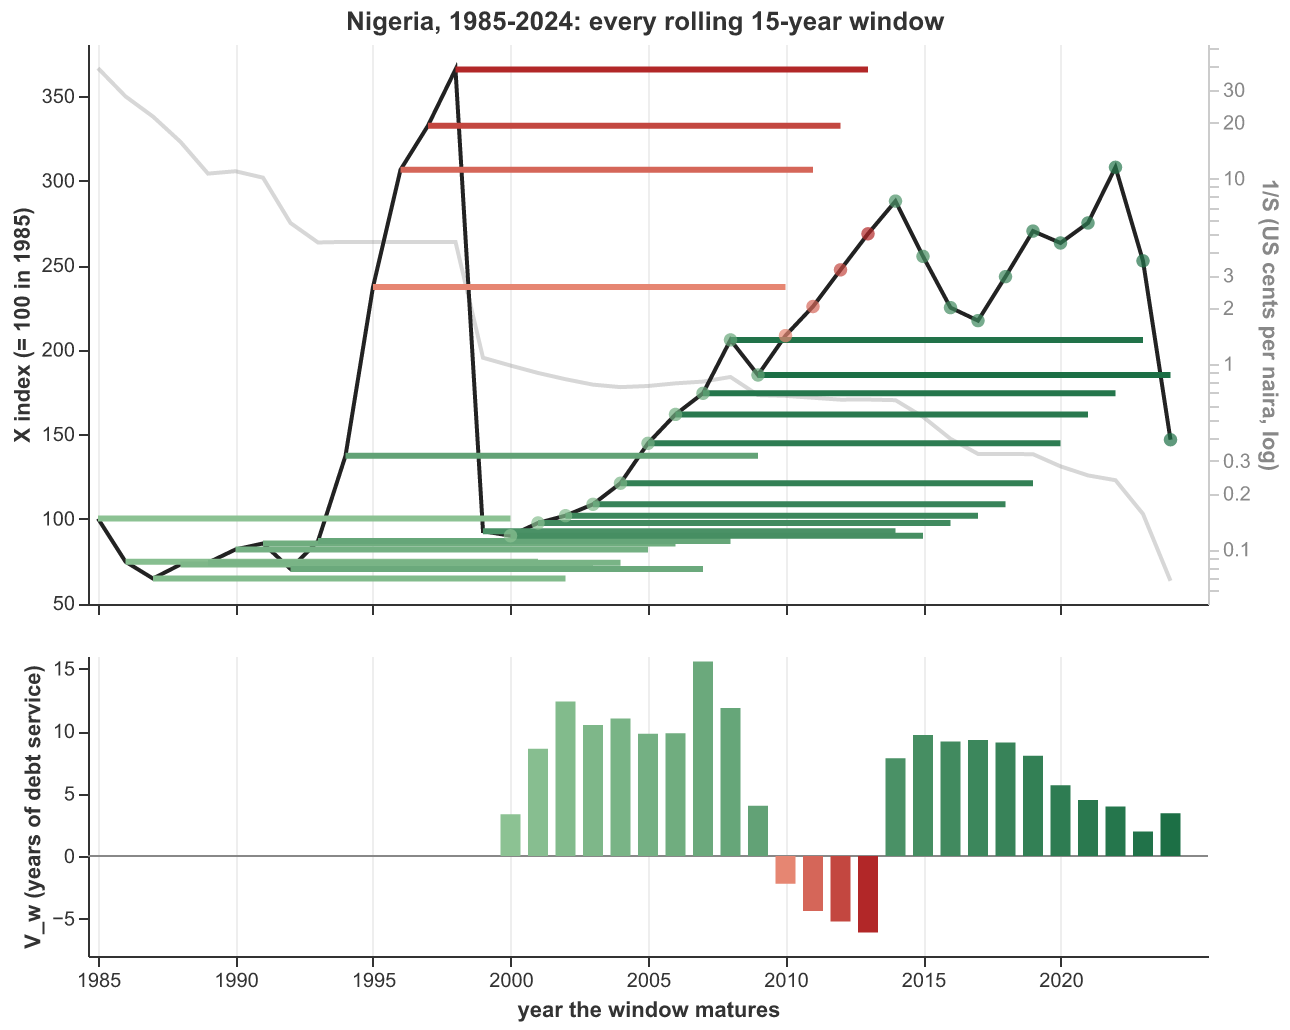

In [4]:
#| label: fig-windows-nga
#| fig-cap: "Nigeria, 1985-2024, every rolling 15-year window. Upper panel, the liquidity leg: $X$ indexed to 100 at 1985 (black), and for each window a horizontal bar at its base-year level $X_{i,\underline{t}}$, running from the base date to maturity, with a dot where $X$ ends. $X$ below the bar is a year the project draws on the Facility; above it, a year it pays into the experience account. Lower panel, the risk leg: the net cover balance $V_w$ at commutation, in years of debt service, plotted under the window's maturity. Green marks a window that commutes with a surplus, red one that leaves the Facility short; within each colour the shade darkens with the base date, so a bar, its dot and its balance are the same window. Four of the 25 windows end short --- those with base dates 1995-1998, into the 1999 abandonment of the dollar peg --- the worst at $V_w=-6.1$. In grey, against the right-hand log axis, the nominal rate $1/S$ in US cents per naira: it falls without interruption from 39.3 cents in 1985 to 0.07 in 2024. That is the path a project with constant *nominal* naira revenue would have been left on, and the distance between it and the black line is what indexing the tariff to domestic inflation recovers."
import numpy as np

# This figure opens the sample in 1985 rather than the draft's 1995: the point
# of it is the naira's 1999 devaluation and the windows that run into it, and a
# 1995 start would leave only the four losing windows and none of the recovery.
NGA_START = 1985

# One country panel, cut once, and handed to the module already cut: the
# dropna and the sort are what window_panel() does to its input anyway, so
# doing them here and passing the result (rather than passing start_year and
# re-filtering df a second time for the line) leaves a single definition of
# which observations this figure is drawn from. The plotted path and the
# windows cannot then be cut from different data.
nga = (df[(df.iso3 == "NGA") & (df.year >= NGA_START)]
       .dropna(subset=["X"]).sort_values("year"))
wp = cover.window_panel(nga, n=n)
bal = cover.window_balance(wp, rho)

X_0 = float(nga.X.iloc[0])
nga = nga.assign(idx=nga.X / X_0 * 100, cents=nga.usd_per_lcu * 100)
FIRST, LAST = int(nga.year.min()), int(nga.year.max())

pos = bal[bal.V >= 0]
print(f"{len(bal)} windows, {FIRST}-{LAST}: {len(pos)} commute with a surplus "
      f"({pos.V.min():.1f} to {pos.V.max():.1f} yrs), {len(bal) - len(pos)} short "
      f"(worst {bal.V.min():.1f} yrs, closing "
      f"{bal.loc[bal.V < 0, 'window_start'].min()}-{bal.loc[bal.V < 0, 'window_start'].max()})")


def ramp(t, light, dark):
    """Hex colours interpolated light -> dark in RGB, for t in [0, 1]."""
    lo, hi = ([int(c[i:i + 2], 16) for i in (1, 3, 5)] for c in (light, dark))
    mix = np.outer(np.asarray(t, dtype=float), np.subtract(hi, lo)) + lo
    return ["#%02x%02x%02x" % tuple(v) for v in mix.round().astype(int)]


def shades(bal):
    """One hex per window: hue by the sign of V, lightness by close date.

    The lightness is ranked within each hue rather than across all windows, so
    the gradient stays legible even when one side has only a few closes packed
    into a handful of years -- which is exactly the losing side here.
    """
    out = pd.Series(index=bal.index, dtype=object)
    for keep, light, dark in [(bal.V >= 0, "#bae4b3", "#005a32"),
                              (bal.V < 0, "#fcae91", "#a50f15")]:
        if keep.any():
            t0 = bal.loc[keep, "window_start"]
            out[keep] = ramp(0.25 + 0.6 * (t0 - t0.min()) / max(t0.max() - t0.min(), 1),
                             light, dark)
    return out


# Both levels a window contributes to the top panel come off the module's own
# objects: `base` is the base-year level window_balance() carried through, and
# the k = n fixing is by construction the window's last observation -- so the
# dot is placed from wp rather than by looking the maturity year back up in the
# country panel.
mature = wp.loc[wp.k == n, ["window_start", "window_end", "level"]]

wins = bal.merge(mature, on=["window_start", "window_end"]).assign(
    start_idx=lambda d: d.base / X_0 * 100,
    end_idx=lambda d: d.level / X_0 * 100,
    shade=lambda d: shades(d))

# Layers share one scale per channel, so every layer has to carry the *same*
# axis spec: axis=None on any one of them drops the guide for all, and two
# layers whose y fields have different default titles make Vega-Lite blank the
# title. Hence each axis is defined once here and reused by name.
SPAN = alt.Scale(domain=[FIRST, LAST + 1], nice=False)
PAD = 0.05 * (nga.idx.max() - nga.idx.min())
INDEX = alt.Scale(domain=[float(nga.idx.min() - PAD), float(nga.idx.max() + PAD)],
                  zero=False, nice=False)
TICKS = list(range(FIRST, LAST + 1, 5))
top_x = alt.Axis(values=TICKS, labels=False, ticks=True, title=None)
top_y = alt.Axis(title=f"X index (= 100 in {FIRST})")
bot_x = alt.Axis(values=TICKS, labelAngle=0, format="d", title="year the window matures")
bot_y = alt.Axis(title="V_w   (years of debt service)")
hue = alt.Color("shade:N", scale=None, legend=None)
tip = ["window_start", "window_end", alt.Tooltip("V:Q", format="+.2f")]

# --- upper panel: the liquidity leg ------------------------------------------
# Each window is one horizontal rule at its own base-year level. X above the
# rule is a year of surplus, below it a year of drawing.
liquidity = (
    alt.Chart(nga).mark_line(color="#222222", strokeWidth=2).encode(
        x=alt.X("year:Q", scale=SPAN, axis=top_x),
        y=alt.Y("idx:Q", scale=INDEX, axis=top_y),
        tooltip=["year", alt.Tooltip("idx:Q", format=".1f")])
    + alt.Chart(wins).mark_rule(strokeWidth=3).encode(
        x=alt.X("window_start:Q", scale=SPAN, axis=top_x), x2="window_end:Q",
        y=alt.Y("start_idx:Q", scale=INDEX, axis=top_y), color=hue, tooltip=tip)
    + alt.Chart(wins).mark_point(filled=True, size=45).encode(
        x=alt.X("window_end:Q", scale=SPAN, axis=top_x),
        y=alt.Y("end_idx:Q", scale=INDEX, axis=top_y), color=hue, tooltip=tip)
).properties(width=560, height=280)

# --- the nominal rate, as background -----------------------------------------
# 1/S on its own right-hand axis, grey and faint, and layered first so it sits
# behind everything else. It carries no part of the argument: it is here only
# so the reader can see the naira's continuous slide -- 39.3 US cents in 1985
# to 0.07 in 2024 -- against which X holds its level. That gap is what tariff
# indexation buys, and the eye should get it from the picture before the text
# makes the point.
#
# The axis is logarithmic. On a linear one the slide would be a cliff before
# 1995 and flat on the floor for the last twenty-five years, which would read
# as a currency that stopped falling rather than one that never did.
#
# resolve_scale(y="independent") has to be applied to a layer whose OTHER
# member is the finished upper panel, not to the four layers individually:
# those four share INDEX deliberately, and resolving y independently across
# all five would give each of them its own axis.
CENTS = alt.Scale(type="log", nice=False,
                  domain=[float(nga.cents.min()) * 0.75,
                          float(nga.cents.max()) * 1.35])
fx_y = alt.Axis(title="1/S   (US cents per naira, log)", orient="right",
                grid=False, format=".3~f", labelColor="#888888",
                titleColor="#888888", tickColor="#cccccc", domainColor="#cccccc")
naira = alt.Chart(nga).mark_line(color="#9a9a9a", strokeWidth=2, opacity=0.4).encode(
    x=alt.X("year:Q", scale=SPAN, axis=top_x),
    y=alt.Y("cents:Q", scale=CENTS, axis=fx_y),
    tooltip=["year", alt.Tooltip("cents:Q", format=".3f", title="US cents per naira")])

liquidity = alt.layer(naira, liquidity).resolve_scale(y="independent")

# --- lower panel: the risk leg -----------------------------------------------
# V_w sits under the maturity of its own window, in the shade of its own rule.
risk = (
    alt.Chart(wins).mark_rule(color="#888888").encode(y=alt.YDatum(0, axis=bot_y))
    + alt.Chart(wins).mark_bar(width=10).encode(
        x=alt.X("window_end:Q", scale=SPAN, axis=bot_x),
        y=alt.Y("V:Q", axis=bot_y), color=hue, tooltip=tip)
).properties(width=560, height=150)

alt.vconcat(liquidity, risk).resolve_scale(x="shared").properties(
    title=alt.TitleParams(f"Nigeria, {FIRST}-{LAST}: every rolling {n}-year window",
                          anchor="middle"))


## The fair premium on the risk leg

For a project taking out the emergency liquidity facility during a window $w=(i,\underline t)$ for a tenor $n$, a positive terminal balance on the experience account ($V_w(n)\geq 0$) is paid out to the project. A negative terminal balance ($V_w(n) <0$) is the loss incurred by the Facility, measured in years of debt service. Measured in dollars, the *ultimate net loss* from window $w$ is
$$
L_w(n) \;=\; \bar\delta \cdot (-V_w(n))^+
$$
This can only be non-negative and it turns out to be strictly positive only in a minority of windows. In the Nigerian experience described above, the facility would have incurred an ultimate net loss only on projects insured over 4 of the 25 windows in the sample.

Since the risk leg of the Facilty makes losses some of the time and profits none of the time, it must charge a premium to cover its expected loss over the portfolio that it insures.

The **pure premium** over a pool of windows $\mathcal{W}$ is the expected ultimate net loss over that pool,
$$
\mathbb{E}[L_w(n)] = \mathbb{E}\big[\bar\delta_w \cdot (-V_w(n))^+\big]
$$
Assuming that a similar amount of debt service $\bar\delta_w$ is covered in each window (a balanced portfolio over the pool), the expectation is estimated by the sample mean over the pool. Setting $N=\vert\mathcal{W}\vert$, we get
$$
\mathbb{E}_N[L_w(n)] \;=\; \bar\delta\,\Theta(n),
\qquad
\Theta(n) \;\equiv\; \frac{1}{N}\sum_{w\in\mathcal{W}} (-V_w(n))^+
$$
where the *expected loss* $\Theta(n)$ carries the unit of $V_w(n)$ itself: it is the expected loss measured in **years of debt service**.

In actuarial terms this is a *burning-cost* estimate: averaged over the historical windows (albeit, over a single currency). In the chart above it is the average depth of the red windows with the positive ones counted as zero.

The actuarially fair **level annual premium** --- the running fee the facility needs to charge the project for the cover --- is the annuity equivalent of that loss. Expressed as a fraction of the annuity paid as debt service, it is
$$
\Psi(n) \;=\; \frac{\mathbb{E}_N[L_w(n)]}{\bar\delta\cdot A_{n,\rho}} \;=\; \frac{\Theta(n)}{A_{n,\rho}}
$$

Going back up to the Nigerian data, and taking a simple average over the 25 historical windows as an indication of future losses (the burning cost estimate), the expected loss is the sum of the 4 red bars divided by 25, the number of windows in the sample, which yields $\Theta = 0.72$ years of debt service.

Spread over the fifteen payments at a discount rate $\rho=5\%$ the annuity factor is $A_{15,5\%}=10.38$ and $\Psi = 6.9\%$. A Nigerian project buying cover priced off a purely Nigerian pool would pay, either $0.72$ years of debt service up front, or 6.9% on top of each of its debt service payments, to the Facility for the latter to take the downside macroeconomic risk off the former's balance sheet.



51 countries; 37 start in 1985, 14 later, the last in 2009


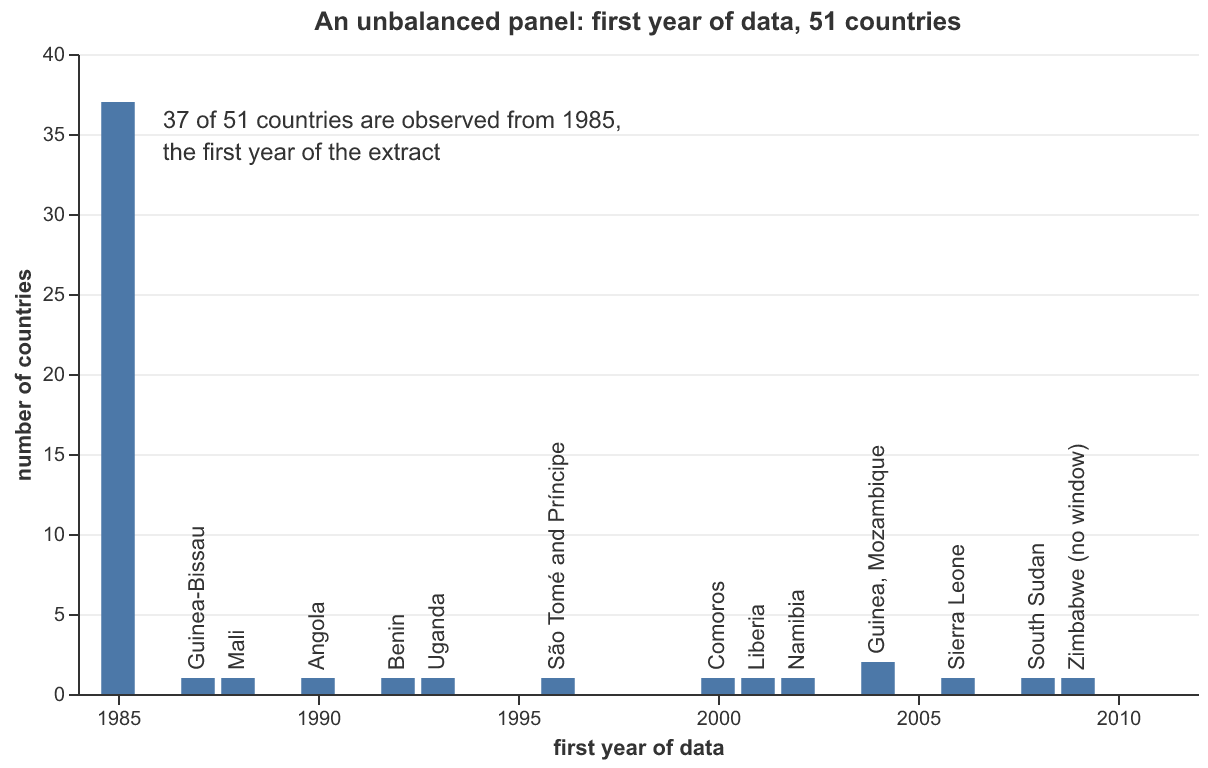

In [5]:
#| label: fig-panel-start
#| fig-cap: "First year of data in the WDI panel, by country: the 51 countries with both a price level and an exchange rate (Lesotho excluded; Eritrea and Somalia never have both). 37 of the 51 countries are observed from 1985, the first year of the extract; the other 14 enter one or two at a time, most of them after a war, a currency reform or independence. A country needs data from 2009 at the latest to fill a single 15-year window by 2024 (dashed): South Sudan just makes it, with two, while Zimbabwe, whose series also stops in 2022, has none and drops out of the pool. The panel is unbalanced at the other end too: the Democratic Republic of Congo stops in 2016, Eswatini in 2019 and Sudan in 2022, and Djibouti has 28 of the 40 years."
# One row per country: the first and last year in which X is defined. That is
# what decides how many windows a country contributes, so it is counted off X
# rather than off either of its components.
span = (df.dropna(subset=["X"]).groupby(["iso3", "country"]).year
          .agg(first="min", last="max", years="count").reset_index())

# Bars are drawn from pandas counts, one year wide, rather than binned in
# Altair, so the name labels can sit on exactly the same x as their bar.
# Each bar is centred on its year.
starts = (span.groupby("first")
              .agg(count=("iso3", "size"),
                   names=("country", lambda s: ", ".join(sorted(s))))
              .reset_index()
              .assign(lo=lambda d: d["first"] - 0.42, hi=lambda d: d["first"] + 0.42))
LAST_BASE = int(df.year.max()) - n          # last base date with a full window
late = starts[starts["first"] > int(df.year.min())].copy()
late["label"] = late.names.replace({
    "Zimbabwe": "Zimbabwe (no window)",
    "Sao Tome and Principe": "São Tomé and Príncipe",
})

print(f"{len(span)} countries; {starts['count'].iloc[0]} start in {starts['first'].iloc[0]}, "
      f"{late['count'].sum()} later, the last in {span['first'].max()}")

# The x range follows the data, so a late starter cannot fall off the edge.
x_hi = max(int(span["first"].max()), LAST_BASE) + 2
x = alt.X("lo:Q", title="first year of data",
          scale=alt.Scale(domain=[int(span["first"].min()) - 1, x_hi]),
          axis=alt.Axis(format="d", values=list(range(1985, x_hi + 1, 5)), grid=False))

bars = alt.Chart(starts).mark_bar(color=BLUE).encode(
    x=x, x2="hi:Q",
    y=alt.Y("count:Q", title="number of countries", scale=alt.Scale(domain=[0, 40])),
    y2=alt.datum(0),
    tooltip=[alt.Tooltip("first:Q", title="first year", format="d"),
             alt.Tooltip("count:Q", title="countries"), "names:N"])

# The late entrants are few enough to name one by one: each label stands
# upright on its own bar.
names = alt.Chart(late).mark_text(
    angle=270, align="left", baseline="middle", dx=4, fontSize=11, color="#333333"
).encode(x="first:Q", y="count:Q", text="label:N")

head = alt.Chart(starts.head(1)).mark_text(
    align="left", baseline="top", dx=14, dy=4, fontSize=12, color="#333333"
).encode(x="hi:Q", y="count:Q",
         text=alt.value(f"{starts['count'].iloc[0]} of {len(span)} countries "
                        f"are observed from {int(starts['first'].iloc[0])},"))
head2 = head.encode(text=alt.value("the first year of the extract")).mark_text(
    align="left", baseline="top", dx=14, dy=20, fontSize=12, color="#333333")

cutoff = alt.Chart(pd.DataFrame({"x": [LAST_BASE + 0.5]})).mark_rule(
    color="#888888", strokeDash=[6, 4]).encode(x="x:Q")
cutoff_txt = alt.Chart(pd.DataFrame({"x": [LAST_BASE + 0.5], "y": [40]})).mark_text(
    align="right", baseline="top", dx=-4, fontSize=11, color="#888888", lineBreak="\n"
).encode(x="x:Q", y="y:Q",
         text=alt.value(f"later starts: no full\n{n}-year window by {int(df.year.max())}"))

(bars + names + head + head2).properties(
    width=560, height=320,
    title=f"An unbalanced panel: first year of data, {len(span)} countries")

## A pool of all African currencies

The analysis above prices the risk leg on 25 rolling 15-year windows in a single county: Nigeria. The Facility will want to provide cover to - and pool risk over - a wider set of currencies. To gain some insight on the continental pool (and to increase statistical power), we consider the panel of all countries for which the World Development Indicators (WDI) dataset from the World Bank has price and exchange rate data for. Excluding Lesotho, because of very large uncorrected basket breaks in the price data, Eritrea and Somalia for lack of price data, and Zimbabwe implicitly because the available sample doesn't yield a single 15-year window, this yields an unbalanced 50-country sample starting in 1985 and containing 1,055 rolling 15-year windows. The chart above shows the distribution of countries by start year of the available data. 

Keeping the Facility's cost of capital at $\rho = 5%$, for each window we calculate the *annuitised net cover balance* $\psi_w(n)=V_w(n)/A_{n,\rho}$ for the $n=15$ year windows, and plot the histogram. 

A number of significan points stand out. The distribution is shifted to the right of zero, with the average at 22% (of annual debt service) and skewed to the right tail, with the median below the mean at 18%, the maximum of 211% at 5.5 standard deviations above the median and the minimum of -75% at only 2.7 standard deviations below the median. Compared to a normal distribution it has drifted upwards both in the centre and in the upper tail. 

Only the distribution truncated to the left of zero (in red) is relevant for the calculation of the premium and this accounts for 26% of all windows in the continental sample. The average amongt the negative windows is -15%.

Recall that we are looking at realisations, across all 15 year windows in the continental pool of currencies, of $V_w(15)/A_{15,5\%}$. If we set all the green bars to zero and take the average over the whole list we get minus the actuarially fair level premium $-\Psi(15) = \mathbb{E}[(V_w(15))^+]/A_{15,5\%}$. The premium equals $4.0\%$ (compared with $6.9\%$ on the Nigerian data). Multiplying out the annuity factor yields the expected loss, in years of debt service, of $\Theta(15) = 0.41$.

Focusing on $\Psi$ by scaling out the annuity factor is useful, because it results in an annual cost that is comparable across tenors. It is the unit which will be most useful to put in a finacial model to see whether the cost of the cover is worth the benefit from offloading the macroeconomic risk. It also linear in the change of pool, in that its value on the balanced pool over the Nigerian Naira and the Algerian Dinar is simply the average of the value on the separate pools.

But when doing the quick mental math to evaluate the affordability of the instrument and when discussing the wisdom of this expense with advisors, the financial experts will want to quote the *equivalent interest rate spread*. 

Lets recall that at the borrowers cost of capital $r$, the principal and the annual debt service are related by $D = \bar \delta \cdot A_{n,r}$, both measured in dollars. If we ask ourselves what the additional interest would have to be on the same principal so that debt service increases by $\bar \delta \Psi$ dollars, we get the condition

$$
\frac{ \bar \delta \cdot A_{n,r}}{A_{n,r+\Delta r}} = \bar \delta + \bar \delta \Psi \iff A_{n,\;r+\Delta r} \;=\; \frac{A_{n,r}}{1 + \Psi}
$$

The equivalent interest rate spread is the $\Delta r$ that makes the equation above hold.

Looking again at 15 year tenors, we must choose the base interest rate of the project on top of which the spread is added. For the sake of simplicity, we'll let $r=10%$, which is realistic for a concessional USD DFI loan in many of the potential countries in the pool. At those parameters, the cost of $\Psi = 4.0%$ would be equivalent to $\Delta r= 0.69\%$. 

Holding $\Theta$ and $\Psi$ fixed, the interest rate spread increases with the baseline cost of capital $r$ a project is paying. This is because the fixed additional debt service payment $\Psi$ added on an already higher cost of capital means that each additional rate increment carries more interest repayment over additional annuity payment. At $r=8\%$ the spread is only $\Delta r = 65bp$ while at $r=15\%$ the spread becomes $82bp$ compared with the $69bp$ at $r=10\%$. 

The summary of the cost of cover, for $n=15$ year tenors, a facility discount rate of $\rho=5\%$ and a project cost of capital of $r=10\%$ is given by the table below.


| Quote | Value | Read as |
|---|---|---|
| $\Theta$, expected loss in years of debt service | **0.41** | the primitive: what the Facility expects to be out of pocket at commutation |
| $\Psi$, annual premium | **4.0%** | as share of each debt-service payment |
| $\Delta r$, margin-equivalent spread | **69 bp** | the investor-facing number, on a 15-year annuity-amortising loan |

1,055 windows: E[psi] = +21.8%, median = +17.7%, worst = -75.5%, best = +211.3%;  Psi = 4.0% of annual debt service


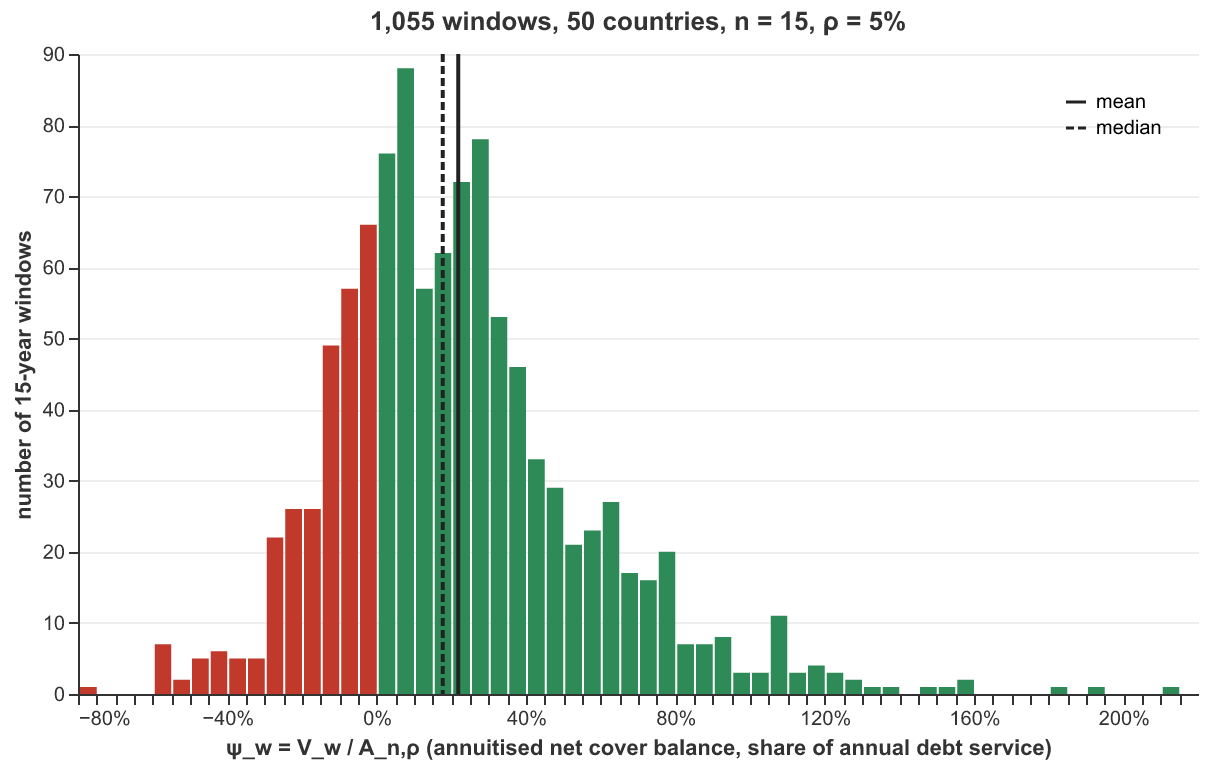

In [6]:
#| label: fig-pool-psi
#| fig-cap: "Annuitised net cover balance $\\psi_w(n)=V_w(n)/A_{n,\\varrho}$, for every rolling 15-year window in the pool ($n=15$, $\\varrho=5\\%$): the terminal balance of the experience account restated as a level annual flow, in shares of one year's debt service. Green: the window commutes in surplus. Red: it ends short, by $\\psi_w$ of debt service every year of the tenor. Solid: the pool mean $\\mathbb{E}_N[\\psi_w]$; dashed: the median. Averaging the red bars, with the green ones counted as zero, gives the fair level annual premium $\\Psi$."
# The same windows as @fig-pool-balance, divided through by one constant, the
# annuity factor A_{n,rho}: the shape cannot change, only the unit -- from
# years of debt service at the base date to a share of each year's payment.
# This cell sits above the pool cell that builds pool_bal, so it builds the
# window panel itself; the psi_ names keep it from colliding with the pool_
# names that cell binds.
psi_bal = cover.window_balance(cover.window_panel(df, n=n, start_year=1985), rho)
psi_bal = psi_bal.assign(
    psi=psi_bal.V / A,
    sign=psi_bal.V.lt(0).map({True: "short", False: "surplus"}))

Psi = psi_bal.psi.clip(upper=0).abs().mean()      # the fair level annual premium
print(f"{len(psi_bal):,} windows: E[psi] = {psi_bal.psi.mean():+.1%}, "
      f"median = {psi_bal.psi.median():+.1%}, worst = {psi_bal.psi.min():+.1%}, "
      f"best = {psi_bal.psi.max():+.1%};  Psi = {Psi:.1%} of annual debt service")

# As in @fig-pool-balance, colour comes from a column, and the bin step (5% of
# a year's debt service) keeps zero on a bin edge so no bar mixes the signs.
psi_hist = alt.Chart(psi_bal).mark_bar().encode(
    x=alt.X("psi:Q", bin=alt.Bin(step=0.05),
            axis=alt.Axis(format=".0%"),
            title="ψ_w = V_w / A_n,ρ   (annuitised net cover balance, share of annual debt service)"),
    y=alt.Y("count():Q", title=f"number of {n}-year windows"),
    color=alt.Color("sign:N", legend=None,
                    scale=alt.Scale(domain=["short", "surplus"], range=[RED, GREEN])),
    tooltip=["sign:N", alt.Tooltip("count():Q", title="windows")])

# Mean solid, median dashed, as in @fig-psi-tenor.
psi_stats = pd.DataFrame({"stat": ["mean", "median"],
                          "psi": [psi_bal.psi.mean(), psi_bal.psi.median()]})
psi_mean = alt.Chart(psi_stats).mark_rule(color="#222222", strokeWidth=2).encode(
    x="psi:Q",
    strokeDash=alt.StrokeDash("stat:N", title=None,
                              scale=alt.Scale(domain=["mean", "median"],
                                              range=[[1, 0], [4, 2]]),
                              legend=alt.Legend(orient="top-right")),
    tooltip=[alt.Tooltip("stat:N"), alt.Tooltip("psi:Q", format=".1%", title="ψ")])

(psi_hist + psi_mean).properties(
    width=560, height=320,
    title=f"{len(psi_bal):,} windows, {psi_bal.country.nunique()} countries, "
          f"n = {n}, ρ = {rho:.0%}")

## The cost of the liquidity leg

If a covered project weren't subject to any risk other than the currency mismatch, the cover provided by the facility would ensure that the project makes it to maturity without defaulting. In that case, the project would be paying in $n$-years of premiums worth a fraction $\Psi(n)$ of the annual debt service payment, and the facility would ensure that the project is always able to meet its dollar debt service obligations. For the facility this results in an expected loss of $\Theta(n)$ years of debt service from those windows that end with a negative balance on the experience account. At the facility's cost of capital, $\rho$, $\Theta(n)$ up front is equivalent to an annual payment of $\Psi(n)$, so it operates at no loss.

The reasoning above applies *if the project makes it to maturity*, as it is based on the commutation of the experience account at the end of the tenor. But the project draws on cheap liquidity from the facility throughout the tenor, whenever the dollar unit-revenue index is below the strike. The facility charges no risk premium on that liquidity. This is certainly defensible if one simply assumes that the project will make it to maturity. In light the possibility of default from other sources of credit risk, this must be evaluated. 

Let us fix the tenor of the debt to $n$, and denote by $\tau < n$ the time of a possible default.

Conditional on a default before maturity, both the income to the facility and its expected loss change. In present value terms, if the project defaults just after $\tau < n$ years, the facility will have accrued $A_{\tau, \rho}\Psi(n)$ in premiums and is left with a loss of $(-V_w(\tau))^+$. In expectation, an early default creates an unpriced (additional) loss for the facility if

$$
\Psi(n) < \frac{\mathbb{E}\left[(-V_w(\tau))^+\right]}{A_{\tau, \rho}} = \Psi(\tau)
$$

Another way of stating the same thing is that the liquidity leg generates credit risk for the facility that is not being priced (neither through the insurance premium nor a risk premium on the interest rate for that liquidity) if and only if the risk leg for shorter tenors $\tau <n$ is more expensive. If that is the case, when projects default after $\tau$ years, they will have paid in less in premium than they leave on average as a negative balance in the experience account. Conversely, if $\Psi(\tau)$ is the same as $\Psi(n)$ or smaller, no credit risk is born by the facility through the provision of the emergency liquidity that is not already priced in through the calculation of the risk leg on the full tenor.

The figure below plots $\Psi(k)$ for $k=1,\ldots, 15$. The cost has a hump shaped profile over the tenor. It starts at $3.4\%$ of annual debt service in year 1, goes up to a peak of $4.5\%$ in year 9 before falling back down $4.0\%$ at the 15 year tenor. 

To calculate the actual cost of early default, and thus the exact credit risk to the facility, we could look at default profiles for certain types of projects, and take an average over $k$ of $\Psi(k)$ weighted by survival probabilities. Such profiles exist in the literature and place the highest default risk in the early years of the project, before operations get streamlined and the unit economics are established. But what is striking about the profile in the figure below is the modest range found in the data. The difference between $4.0\%$ at $n=15$ and the maximum of $4.5\%$ does not materially change our conclusion that the facility can offer this product quite affordably. In fact, liquidity risk has a very small effect on the economics of this product.

It is instructive to look at the structure of the underlying distribution over time. In the lower panel we plot the distribution of $\psi(k)$ across tenor length. These are the same distributions as the one shown above for $n=15$.

The main drivers of the distribution's evolution are clearly visible. Recall that these are the annuitised value of the terminal balance of the experience account for tenors of increasing length: $\psi(k) = \frac{V_m(k)}{A_{k,5\%}}$, plotted for all available windows $w$.

First, the mean and median are growing, reaching 22% and 18% respectively for $n=15$ year tenors. The denominator $A_{k,5\%}$ grows non-linearly, so we don't dwell on the specific growth rates. Just to add that both median and mean grow througout, and the mean grows more quickly, which indicates that the weight is shifting to the right tail.

At the same time, the distribution is spreading out (more volatility the outcomes), by more above the median than below it, as just noted.

The net effect is that the fraction below zero (at which the balance of the experience account is negative and the facility incurrs a loss) is steadily shrinking, from 38\% at $k=1$ to 26\% at $k=15$. That is mostly due to the growth of the mean. At the same time, the average loss, conditional on the balance being negative, grows initially from -9.0% of debt service at $k=1$ to -14.1% of debt service in year 8 and flattens out afterward to reach -15.1% in year 15.

The hump shape of $\Psi(k)$ is due to the fact that fraction of losses continues to shrink while the bottom tail in that fraction stops spreading.

1,055 windows at every tenor;  Psi(1) = 3.4%, peak Psi(9) = 4.5%, Psi(15) = 4.0%;  short: 38% at 1 yr, 26% at 15
not drawn: 40 of 15,825 window-tenors above 150%, all in surplus


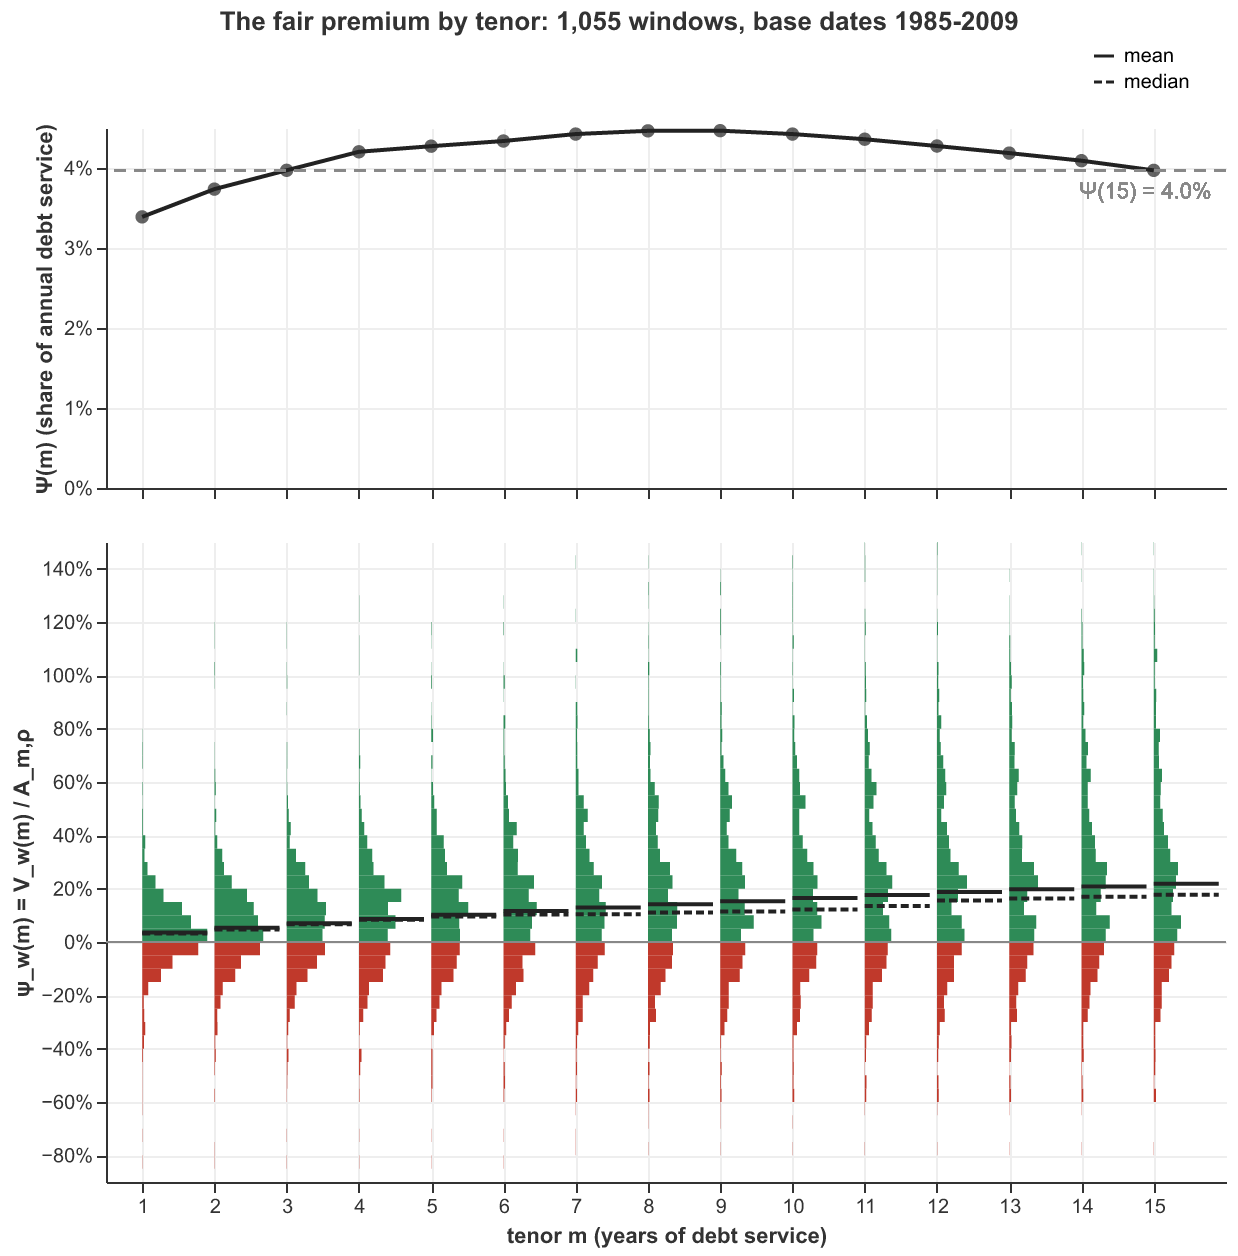

In [10]:
#| label: fig-psi-tenor
#| fig-cap: "The fair level annual premium by tenor, on a fixed pool: the 1,055 windows with base dates 1985-2009 that have a full 15 years of data, each cut at every tenor $m=1,\\dots,15$ so that shorter tenors add no new cohorts. Upper panel: $\\Psi(m)=\\frac{1}{N}\\sum_w(-\\psi_w(m))^+$, in shares of annual debt service; dashed, the 15-year premium $\\Psi(15)$. Lower panel: at each tenor, the distribution of the annuitised balance $\\psi_w(m)=V_w(m)/A_{m,\\varrho}$, as a histogram turned on its side, bars running right from the tenor and the length of each bar the number of windows in it. Red: windows that would commute short at that tenor. Green: windows in surplus. Black ticks across each histogram: solid, the mean $\\mathbb{E}_N[\\psi_w(m)]$; dashed, the median. The axis stops at 150%: the 40 window-tenors above it, of 15,825, are all in surplus."
# Every tenor is priced on the same windows: the n-year panel, cut short. V_w(m)
# is the experience account after m years, sum_{k<=m} R_w(k)(1+rho)^-k -- the
# partial sum of the very terms window_balance() adds up for V_w(n), so at m = n
# the two agree exactly. Re-running window_panel() at each shorter tenor would
# instead let in base dates after 2009, and windows that only exist because a
# country's series stops early, and Psi(m) would then move with the pool as well
# as with the tenor.
n=15
ten_wp = cover.window_panel(df, n=n, start_year=1985)
ten_wp = ten_wp.assign(pv=ten_wp.R * (1 + rho) ** -ten_wp.k).sort_values(
    ["iso3", "window_start", "k"])
ten_wp["V_m"] = ten_wp.groupby(["iso3", "window_start"]).pv.cumsum()
ten_wp["psi"] = ten_wp.V_m / ten_wp.k.map(lambda m: cover.annuity(m, rho))

ten = (ten_wp.groupby("k").psi
             .agg(Psi=lambda s: s.clip(upper=0).abs().mean(),
                  p_short=lambda s: (s < 0).mean(), N="size")
             .reset_index())
Psi_n = float(ten.loc[ten.k == n, "Psi"].iloc[0])
peak = ten.loc[ten.Psi.idxmax()]
print(f"{int(ten.N.iloc[0]):,} windows at every tenor;  Psi(1) = {ten.Psi.iloc[0]:.1%}, "
      f"peak Psi({int(peak.k)}) = {peak.Psi:.1%}, Psi({n}) = {Psi_n:.1%};  "
      f"short: {ten.p_short.iloc[0]:.0%} at 1 yr, {ten.p_short.iloc[-1]:.0%} at {n}")

# The sideways histograms are drawn as rectangles from pandas counts, as in
# @fig-panel-start: a bin of psi on the y-axis, and a bar running right from
# x = m whose length is the count, scaled so the longest bar in the whole
# panel is WIDTH tenors wide. One scale for all fifteen, so the bars shorten as
# the distribution spreads out with tenor. A step of 5% keeps zero on a bin
# edge, so no bar mixes the two signs. The y-axis stops at PSI_MAX: the few
# windows above it are a thin upper tail that would otherwise squash the body
# of every histogram into the bottom third of the panel; they are counted in
# the printout rather than drawn.
STEP, WIDTH = 0.05, 0.9
PSI_MIN, PSI_MAX = -0.9, 1.5
above = ten_wp.psi >= PSI_MAX
print(f"not drawn: {above.sum()} of {len(ten_wp):,} window-tenors above {PSI_MAX:.0%}, "
      f"all in surplus")
hist = (ten_wp[~above].assign(lo=np.floor(ten_wp.psi / STEP) * STEP)
              .groupby(["k", "lo"]).size().rename("count").reset_index())
hist = hist.assign(hi=hist.lo + STEP,
                   x0=hist.k.astype(float),
                   x1=hist.k + WIDTH * hist["count"] / hist["count"].max(),
                   sign=np.where(hist.lo < 0, "short", "surplus"))

# Mean and median of psi_w(m) at each tenor, on all windows (including those
# above PSI_MAX), drawn as ticks spanning the width of that tenor's histogram.
stats = (ten_wp.groupby("k").psi.agg(mean="mean", median="median")
               .reset_index()
               .melt(id_vars="k", var_name="stat", value_name="psi"))
stats = stats.assign(x0=stats.k.astype(float), x1=stats.k + WIDTH)

TENOR = alt.Scale(domain=[0.5, n + 1], nice=False)
ten_top_x = alt.Axis(values=list(range(1, n + 1)), labels=False, ticks=True, title=None)
ten_bot_x = alt.Axis(values=list(range(1, n + 1)), labelAngle=0, format="d",
                     title="tenor m   (years of debt service)")
ten_top_y = alt.Axis(format=".0%", title="Ψ(m)   (share of annual debt service)")
ten_bot_y = alt.Axis(format=".0%", title="ψ_w(m) = V_w(m) / A_m,ρ")

# --- upper panel: the premium -----------------------------------------------
premium = (
    alt.Chart(ten).mark_line(color="#222222", strokeWidth=2).encode(
        x=alt.X("k:Q", scale=TENOR, axis=ten_top_x),
        y=alt.Y("Psi:Q", axis=ten_top_y, scale=alt.Scale(zero=True)))
    + alt.Chart(ten).mark_point(filled=True, size=45, color="#222222").encode(
        x=alt.X("k:Q", scale=TENOR, axis=ten_top_x),
        y=alt.Y("Psi:Q", axis=ten_top_y),
        tooltip=[alt.Tooltip("k:Q", title="tenor"),
                 alt.Tooltip("Psi:Q", format=".2%", title="Ψ(m)"),
                 alt.Tooltip("p_short:Q", format=".0%", title="share short")])
    + alt.Chart(ten).mark_rule(color="#888888", strokeDash=[6, 4]).encode(
        y=alt.YDatum(Psi_n, axis=ten_top_y))
    + alt.Chart(ten).mark_text(align="right", baseline="top", dy=5, fontSize=11,
                               color="#888888").encode(
        x=alt.XDatum(n + 0.8, scale=TENOR, axis=ten_top_x),
        y=alt.YDatum(Psi_n, axis=ten_top_y),
        text=alt.value(f"Ψ({n}) = {Psi_n:.1%}"))
).properties(width=560, height=180)

# --- lower panel: the distribution behind it --------------------------------
spread = (
    alt.Chart(hist).mark_rect().encode(
        x=alt.X("x0:Q", scale=TENOR, axis=ten_bot_x), x2="x1:Q",
        y=alt.Y("lo:Q", axis=ten_bot_y,
                scale=alt.Scale(domain=[PSI_MIN, PSI_MAX], nice=False)), y2="hi:Q",
        color=alt.Color("sign:N", legend=None,
                        scale=alt.Scale(domain=["short", "surplus"], range=[RED, GREEN])),
        tooltip=[alt.Tooltip("k:Q", title="tenor"),
                 alt.Tooltip("lo:Q", format=".0%", title="ψ from"),
                 alt.Tooltip("hi:Q", format=".0%", title="ψ to"),
                 alt.Tooltip("count:Q", title="windows")])
    + alt.Chart(hist).mark_rule(color="#888888").encode(y=alt.YDatum(0, axis=ten_bot_y))
    + alt.Chart(stats).mark_rule(color="#222222", strokeWidth=2).encode(
        x=alt.X("x0:Q", scale=TENOR, axis=ten_bot_x), x2="x1:Q",
        y=alt.Y("psi:Q", axis=ten_bot_y),
        strokeDash=alt.StrokeDash("stat:N", title=None,
                                  scale=alt.Scale(domain=["mean", "median"],
                                                  range=[[1, 0], [4, 2]]),
                                  legend=alt.Legend(orient="bottom-right")),
        tooltip=[alt.Tooltip("k:Q", title="tenor"), alt.Tooltip("stat:N"),
                 alt.Tooltip("psi:Q", format=".1%", title="ψ")])
).properties(width=560, height=320)

alt.vconcat(premium, spread).resolve_scale(x="shared").properties(
    title=alt.TitleParams(f"The fair premium by tenor: {int(ten.N.iloc[0]):,} windows, "
                          f"base dates 1985-2009", anchor="middle"))

## The cost

Earlier we computed the cost on just Nigerian data (producing $\Psi = 6.9\%$ of debt service and $\Delta r = 1.2\%$ per annum additional interest equivalent) and just below we will consider the economics to different sub-pools of African currencies. But the analysis of the full continental pool has the benefit of bringing together the whole experience (and a significant set of data points) of the last 30 years on the continent, averaging the impacts across basket cases such as Lybia and paragons of stability such as Botswana.

We find that it is possible to provide exchange rate cover to long tenor debt on the African continent very cheaply. This runs contrary to the widespread interpretation of the data. Under that interpretation local currency hedges are too expensive as these nominal instruments have to account for large interest rate differentials that result in double digit expected annual depreciation rates. The lower interest rate in the hard currency being the whole point, the hedge gives away the whole differential as the cost of offloading the volatility and so they don't get purchased. Transactions only take place when the currency mismatch has been placed on some other entity, such as the off-taker, resulting in the financial woes of those institutions. And if a hard currency loan does take place, the owners try hard to refinance in local currency as soon as the credit risk has come down after COD, realising at the spot rate and swapping the low hard currency interest with the volatility of the mismatch for the high local currency interest and certainty.

In fact, all it takes is for some institution to be willing to wait for local currency inflation to move the conbined exposure back into neutral territory, which is exactly what the liquidity facility does. In all episodes in the data in which the local currency lost more that 20% against the dollar in a year (163 of 1,819 country-years in the data) the median drop in $X$ was only 11% in the same year and regained 11% in the next 5 years on average. The large drops are not repeated, because inflation all but surely follows the devaluation. A facility that can provide the liquidity to wait that out will get its money back most of the time.

## A useful comparison



## Country by country

The figure below prices the Facility's instrument on each country's own windows, in terms of fair level annual premium $\Psi$ in the upper panel and in terms of margin-equivalent spread $\Delta r$.

It is worth highlighting that there are several countries with zero burn cost. These countries did not have a single window that ended in a negative net cover balance in the last 30 years. 

Only two countries would require pricing over 10% of annual debt service based on their historical data: Libya and the Democratic Republic of Congo, both war zones for much of the sample. Dropping only these two brings the premium to $\Psi = 3.4\%$ or $\Delta r = 0.6\%$ (compared with 4.0% and 0.69% on the full pool).

The annual premium is linear in individual windows, so the value for a particular pool can be visually estimated by taking the average across the bars.

50 countries, 1,055 windows: pooled Psi = 4.0%, delta_r = 69bp;  median country Psi = 2.7%, delta_r = 47bp;  8 at zero


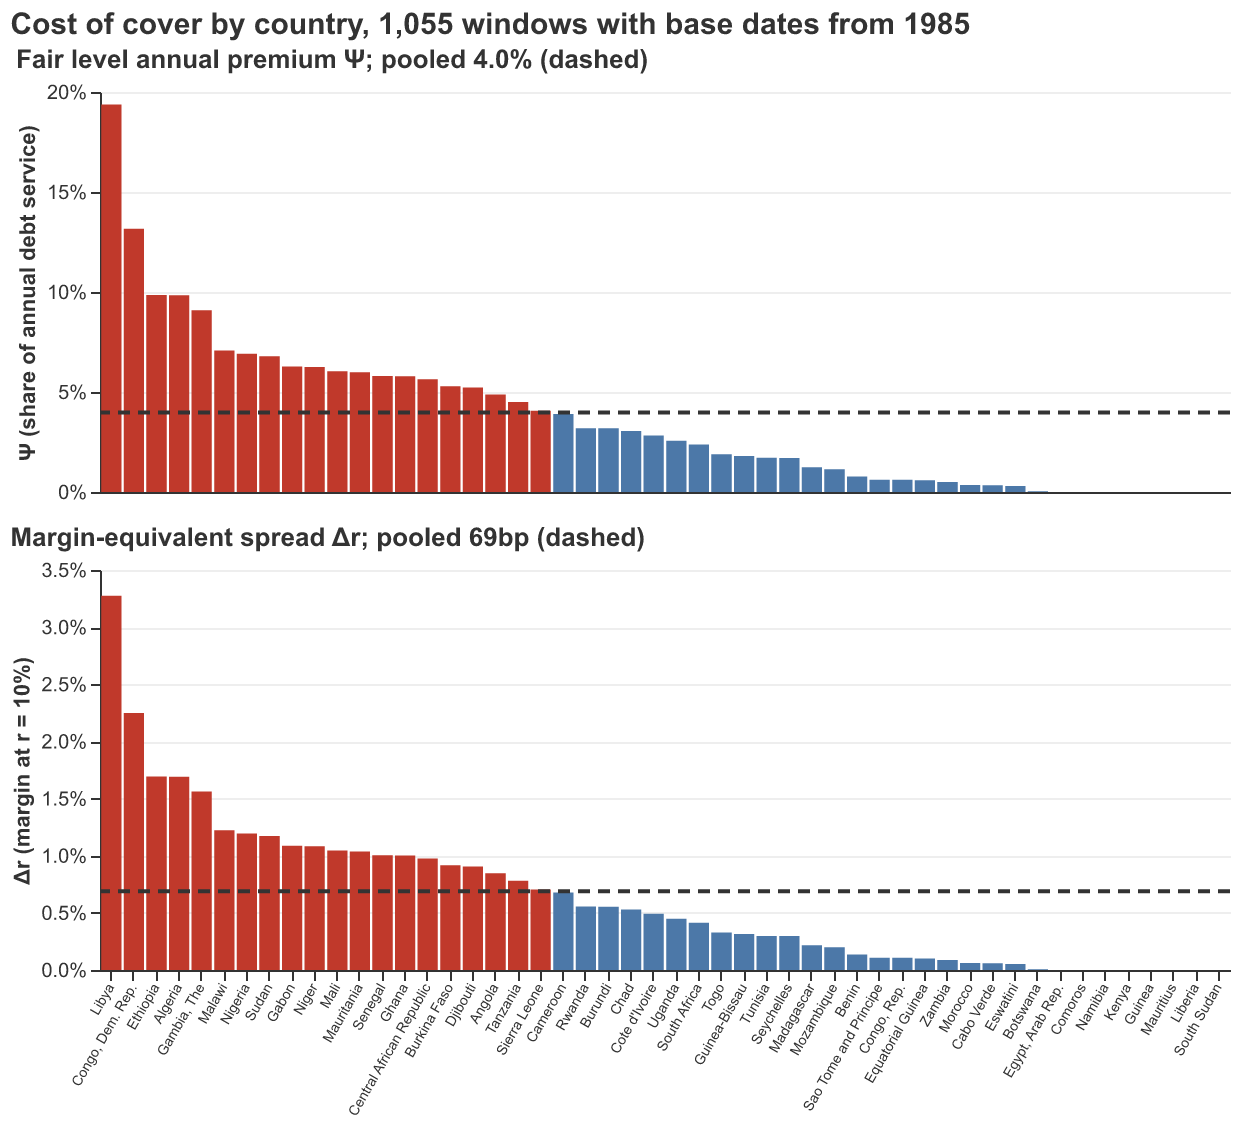

In [17]:
#| label: fig-country-spread
#| fig-cap: "The Facility's cover priced country by country, on each country's own rolling 15-year windows with base dates from 1985 ($n=15$, $\varrho=5\%$). Upper panel: the fair level annual premium $\Psi$, as a share of each year's debt service. Lower panel: the same premium restated as the margin-equivalent spread $\Delta r$ on a 15-year annuity-amortising loan at $r=10\%$. Countries are in the same order in both panels. Dashed line: the pooled price; red bars price above it."
# Country-level counterpart of the pool cell below: the same window panel,
# priced once per country by price_by() instead of once for the whole pool.
# It sits above that cell, so it builds its own balances; the cty_ names keep
# it from colliding with the pool_ names bound there.
cty_bal = cover.window_balance(cover.window_panel(df, n=n, start_year=1985), rho)
cty_pool = cover.price(cty_bal, n, rho, r=r)
cty = cover.price_by(cty_bal, ["iso3", "country"], n, rho, r=r)

print(f"{len(cty)} countries, {cty_pool['n_windows']:,} windows: pooled Psi = {cty_pool['psi']:.1%}, "
      f"delta_r = {cty_pool['delta_r'] * 1e4:.0f}bp;  median country Psi = {cty.psi.median():.1%}, "
      f"delta_r = {cty.delta_r.median() * 1e4:.0f}bp;  {(cty.psi == 0).sum()} at zero")

# Delta r is monotone in Psi at fixed n and r, so one ordering serves both
# panels and a column is the same country top and bottom.
cty_order = cty.sort_values("psi", ascending=False)["country"].tolist()
cty_tip = ["country", "n_windows",
           alt.Tooltip("psi:Q", title="Ψ (share of debt service)", format=".1%"),
           alt.Tooltip("delta_r:Q", title="Δr", format=".2%"),
           alt.Tooltip("p_loss:Q", title="P(V < 0)", format=".0%"),
           alt.Tooltip("mean_V:Q", title="mean V (yrs of debt service)", format="+.2f")]


def cty_panel(col, title, fmt, show_x):
    pooled = cty_pool[col]
    x_axis = (alt.Axis(labelAngle=-60, labelFontSize=7, labelOverlap=False, title=None) if show_x
              else alt.Axis(labels=False, ticks=False, title=None))
    bars = alt.Chart(cty).mark_bar().encode(
        x=alt.X("country:N", sort=cty_order, axis=x_axis),
        y=alt.Y(f"{col}:Q", axis=alt.Axis(format=fmt), title=title),
        color=alt.condition(alt.datum[col] > pooled, alt.value(RED), alt.value(BLUE)),
        tooltip=cty_tip)
    rule = alt.Chart(pd.DataFrame({col: [pooled]})).mark_rule(
        color="#333", strokeDash=[6, 4], strokeWidth=2).encode(y=f"{col}:Q")
    return (bars + rule).properties(width=565, height=200)


alt.vconcat(
    cty_panel("psi", "Ψ  (share of annual debt service)", ".0%", False).properties(
        title=alt.TitleParams(f"Fair level annual premium Ψ;  pooled {cty_pool['psi']:.1%} (dashed)",
                              anchor="start")),
    cty_panel("delta_r", f"Δr  (margin at r = {r:.0%})", ".1%", True).properties(
        title=alt.TitleParams(f"Margin-equivalent spread Δr;  pooled {cty_pool['delta_r'] * 1e4:.0f}bp (dashed)",
                              anchor="start")),
    spacing=12,
).resolve_scale(x="shared").properties(
    title=alt.TitleParams(f"Cost of cover by country, {cty_pool['n_windows']:,} windows with base dates from 1985",
                          anchor="start", fontSize=15))

## Solvency capital

The facility must hold capital to provide such insurance. We have already argued that a highly rated balance sheet with low capital cost will be able to provide the instrument at a lower cost because it is able to pass on it's low capital cost in the emergency liquidity (we have shown that the credit risk that the liquidity is exposed to is covered by the annual premiums charged). 

A low cost of capital is also important from a solvency requirement.

In [ ]:
#| include: false
# The cost of cover for the whole African pool: the same two calls as the
# Nigerian panel, over every country at once rather than NGA alone. It opens in
# 1985 like that panel, not at the notebook's start_year -- hence the pool_
# names, which must not collide with the Nigerian wp/bal still bound above.
POOL_START = 1985

pool_wp = cover.window_panel(df, n=n, start_year=POOL_START)
pool_bal = cover.window_balance(pool_wp, rho)
pool = cover.price(pool_bal, n, rho, r=r)

# Every quote in the table comes out of one price() call on one window panel,
# so they cannot drift apart: the annuity divisions that separate them all
# happen in there, once. This is also the only place the borrower's rate r is
# used in the notebook. It changes nothing on the cover side -- theta and psi
# come off rho alone -- and enters only where the premium is restated against
# something the borrower pays for: kappa and psi_debt against the principal
# A_{n,r} * delta_bar, and delta_r as a margin on that loan.
print(cover.describe(pool))

short = pool_bal.V[pool_bal.V < 0]
worst = pool_bal.loc[pool_bal.V.idxmin()]
print(f"closes {pool_bal.window_start.min()}-{pool_bal.window_start.max()};  "
      f"median = {pool['median_V']:+.2f};  E[V | V<0] = {short.mean():+.2f};  "
      f"worst = {worst.V:+.2f} ({worst.country}, close {worst.window_start})")

# Liquidity against solvency. window_balance() counts the drawing years off the
# same rows that produced V, so how often the Facility lends and how often it
# loses cannot drift apart either.
draws = pool_bal.any_draw
print(f"draws at some point in {draws.mean():.0%} of windows, for "
      f"{pool_bal.loc[draws, 'n_draw_years'].mean():.1f} of {n} years on average; "
      f"only {pool['p_loss']:.0%} end short")

# Where the affordability comes from: the same windows priced on the real
# exchange rate Q = X / P*, which strips the US price level out of X.
real = cover.price(cover.window_balance(
    cover.window_panel(df, n=n, col="Q", start_year=POOL_START), rho), n, rho, r=r)
print("\nthe same windows priced on Q rather than X:")
print(cover.describe(real), f"  median = {real['median_V']:+.2f}")


N = 1055 windows / 50 countries, n = 15, rho = 5.00%, r = 10.00%
theta = 0.4121 yrs of debt service;  psi = 0.0397 of debt service;  kappa = 0.0542 of principal
psi/A = 52bp flat;  delta_r = 69bp on the margin;  P(V<0) = 26.3%;  E[V] = +2.27
closes 1985-2009;  median = +1.84;  E[V | V<0] = -1.57;  worst = -7.83 (Sudan, close 1991)
draws at some point in 67% of windows, for 6.9 of 15 years on average; only 26% end short

the same windows priced on Q rather than X:
N = 1055 windows / 50 countries, n = 15, rho = 5.00%, r = 10.00%
theta = 1.0328 yrs of debt service;  psi = 0.0995 of debt service;  kappa = 0.1358 of principal
psi/A = 131bp flat;  delta_r = 171bp on the margin;  P(V<0) = 53.3%;  E[V] = +0.15   median = -0.22


In [40]:
#| include: false
# The left tail of @fig-pool-balance, window by window. Sorted on V, so these
# are the fifteen windows that cost the Facility the most at commutation, not
# the fifteen deepest single-year shortfalls -- worst_year is carried alongside
# to show how differently those two rank.
worst15 = pool_bal.nsmallest(80, "V")

print(f"the 15 costliest windows of {pool['n_windows']:,} (rho = {rho:.0%}, n = {n}):")
print(worst15[["country", "window_start", "window_end", "V", "n_draw_years", "worst_year"]]
      .to_string(index=False, header=["country", "close", "maturity", "V_w",
                                      "draw yrs", "worst yr"],
                 formatters={"V": "{:+.2f}".format, "worst_year": "{:+.2f}".format}))
print(f"\nthey carry {worst15.V.abs().sum() / pool['n_windows'] / pool['theta']:.0%} of the "
      f"pool's expected loss of Theta = {pool['theta']:.2f} yrs of debt service, "
      f"and are {len(worst15) / pool['n_windows']:.1%} of the windows")


the 15 costliest windows of 1,055 (rho = 5%, n = 15):
                 country close maturity   V_w draw yrs worst yr
                   Sudan  1991     2006 -7.83       15    -0.84
                 Nigeria  1998     2013 -6.11       15    -0.75
                   Libya  1999     2014 -6.03       15    -0.73
                   Libya  2000     2015 -5.93       15    -0.69
        Congo, Dem. Rep.  1993     2008 -5.92       15    -0.70
                   Sudan  1990     2005 -5.80       14    -0.78
                Ethiopia  1991     2006 -5.79       15    -0.69
                Tanzania  1985     2000 -5.79       15    -0.67
                   Libya  1998     2013 -5.33       14    -0.72
                 Nigeria  1997     2012 -5.23       14    -0.73
                Ethiopia  1992     2007 -5.17       15    -0.62
                  Angola  1990     2005 -5.00       15    -0.78
                   Libya  2001     2016 -4.91       15    -0.60
                   Libya  1997     2012 -4.71     